In [ ]:
#importing necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (
    f1_score, roc_auc_score, roc_curve, auc,
    classification_report, accuracy_score, precision_score, recall_score
)
from sklearn.cluster import KMeans

**Data Collection**

In [ ]:
#Load Dataset
dataset = pd.read_csv("/content/sample_data/consumer_classification_dataset.csv")

In [ ]:
#Summarize data
dataset

,Age,Income,Gender,Marital_Status,Credit_Score,Num_Purchases,Membership_Years,Device_Used,Churn
0,56.0,70201.189680,Female,Married,687.761776,9,12,Desktop,0
1,69.0,51901.897395,Male,Single,712.617115,3,14,Tablet,0
2,46.0,38605.409293,Male,Married,782.299643,5,8,Mobile,0
3,32.0,49949.736955,Female,Single,697.749518,7,1,Tablet,0
4,NaN,48965.290095,Other,Married,663.155216,4,4,Desktop,1
...,...,...,...,...,...,...,...,...,...
1495,40.0,38575.311408,Male,Single,717.997517,3,9,Mobile,0
1496,54.0,47273.370862,Other,Single,678.621530,4,2,Desktop,1
1497,28.0,52600.121356,Other,Divorced,611.316046,2,3,Desktop,0
1498,23.0,63187.644522,Female,Divorced,690.256745,5,7,Tablet,1


In [ ]:
dataset.head(10)

,Age,Income,Gender,Marital_Status,Credit_Score,Num_Purchases,Membership_Years,Device_Used,Churn
0,56.0,70201.189680,Female,Married,687.761776,9,12,Desktop,0
1,69.0,51901.897395,Male,Single,712.617115,3,14,Tablet,0
2,46.0,38605.409293,Male,Married,782.299643,5,8,Mobile,0
3,32.0,49949.736955,Female,Single,697.749518,7,1,Tablet,0
4,NaN,48965.290095,Other,Married,663.155216,4,4,Desktop,1
5,25.0,11326.768555,Female,Divorced,697.061084,1,4,Desktop,1
6,38.0,41579.497114,NaN,Divorced,687.615220,5,6,Tablet,1
7,56.0,54713.055994,Female,Married,714.708713,7,12,Tablet,0
8,36.0,43636.766522,Male,Divorced,540.098369,3,12,Desktop,0
9,40.0,40306.859573,Male,Divorced,NaN,3,2,Mobile,0


In [ ]:
print(dataset)

       Age        Income  Gender Marital_Status  Credit_Score  Num_Purchases  \
0     56.0  70201.189680  Female        Married    687.761776              9   
1     69.0  51901.897395    Male         Single    712.617115              3   
2     46.0  38605.409293    Male        Married    782.299643              5   
3     32.0  49949.736955  Female         Single    697.749518              7   
4      NaN  48965.290095   Other        Married    663.155216              4   
...    ...           ...     ...            ...           ...            ...   
1495  40.0  38575.311408    Male         Single    717.997517              3   
1496  54.0  47273.370862   Other         Single    678.621530              4   
1497  28.0  52600.121356   Other       Divorced    611.316046              2   
1498  23.0  63187.644522  Female       Divorced    690.256745              5   
1499  35.0  47717.000295   Other       Divorced           NaN              5   

      Membership_Years Device_Used  Chu

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
print(type(dataset))

<class 'pandas.core.frame.DataFrame'>


In [ ]:
print("Keys of dataset:\n", dataset.keys())

Keys of dataset:
 Index(['Age', 'Income', 'Gender', 'Marital_Status', 'Credit_Score',
       'Num_Purchases', 'Membership_Years', 'Device_Used', 'Churn'],
      dtype='object')


In [ ]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Age               1425 non-null   float64
 1   Income            1425 non-null   float64
 2   Gender            1425 non-null   object 
 3   Marital_Status    1500 non-null   object 
 4   Credit_Score      1425 non-null   float64
 5   Num_Purchases     1500 non-null   int64  
 6   Membership_Years  1500 non-null   int64  
 7   Device_Used       1500 non-null   object 
 8   Churn             1500 non-null   int64  
dtypes: float64(3), int64(3), object(3)
memory usage: 105.6+ KB


In [ ]:
print(f"There are {dataset.shape[1]} features in the dataset.")

There are 9 features in the dataset.


In [ ]:
print(f"There are {dataset.size} data points.")

There are 13500 data points.


In [ ]:
print(set(dataset.dtypes))

{dtype('O'), dtype('int64'), dtype('float64')}


In [ ]:
df= dataset.copy()

In [ ]:
# Explicitly define the target column based on the problem
target_col = 'Churn'

# Show unique values
print(f"Target column selected: {target_col}")
print("Unique values in the target column:")
print(df[target_col].unique())

# Check data type
print("Data type of target column:", df[target_col].dtype)

# Classification or regression check
if df[target_col].dtype == 'object' or df[target_col].nunique() <= 10:
    print(" This is a Classification Problem.")
else:
    print(" This appears to be a Regression Problem.")

Target column selected: Churn
Unique values in the target column:
[0 1]
Data type of target column: int64
 This is a Classification Problem.


In [ ]:
feature_names = dataset.columns.tolist()
df3 = pd.DataFrame(dataset, columns=feature_names[1:])

In [ ]:
df3 = dataset

quantitative_data = df3.select_dtypes(include=['number'])
quantitative_features = quantitative_data.columns.tolist()

categorical_data = df3.select_dtypes(include=['object'])
categorical_features = categorical_data.columns.tolist()

print(f"No of Quantitative features {len(quantitative_features)}")
print("Quantitative:", quantitative_features)

print(f"No of Categorical features {len(categorical_features)}")
print("Categorical:", categorical_features)

No of Quantitative features 6
Quantitative: ['Age', 'Income', 'Credit_Score', 'Num_Purchases', 'Membership_Years', 'Churn']
No of Categorical features 3
Categorical: ['Gender', 'Marital_Status', 'Device_Used']


**EDA(Exploratory Data Analysis)**

**1.Descriptive Analysis**

In [ ]:
# Transposed stats for quantitative features
quantitative_data.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,1425.0,43.750175,15.026126,18.000000,31.000000,44.000000,56.000000,69.000000
Income,1425.0,50446.150664,15320.475325,-826.421240,40557.251779,50671.503006,60994.627689,98819.709397
Credit_Score,1425.0,648.786794,69.583710,390.384237,601.996211,650.015506,694.954684,906.039126
Num_Purchases,1500.0,5.078667,2.260653,0.000000,3.000000,5.000000,6.000000,16.000000
Membership_Years,1500.0,7.388667,3.974603,1.000000,4.000000,7.000000,11.000000,14.000000
Churn,1500.0,0.495333,0.500145,0.000000,0.000000,0.000000,1.000000,1.000000


In [ ]:
# Transposed stats for categorical features
categorical_data.describe().T

,count,unique,top,freq
Gender,1425,3,Other,486
Marital_Status,1500,3,Divorced,522
Device_Used,1500,3,Desktop,528


In [ ]:
quantitative_data.var()

,0
Age,2.257845e+02
Income,2.347170e+08
Credit_Score,4.841893e+03
Num_Purchases,5.110552e+00
Membership_Years,1.579747e+01
Churn,2.501450e-01


In [ ]:
quantitative_data.skew()

,0
Age,-0.041694
Income,-0.029135
Credit_Score,-0.058151
Num_Purchases,0.485069
Membership_Years,0.016571
Churn,0.018686


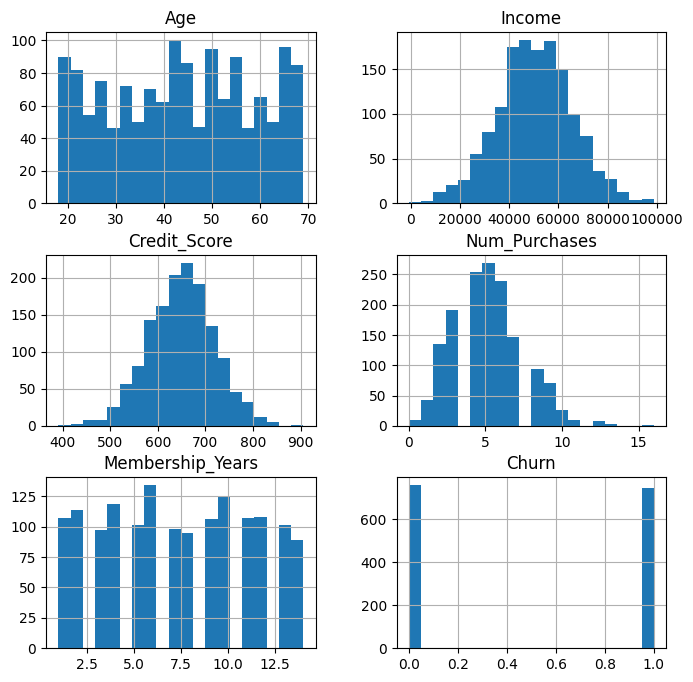

In [ ]:
quantitative_data.hist(figsize=(8,8),bins=20)
plt.show()

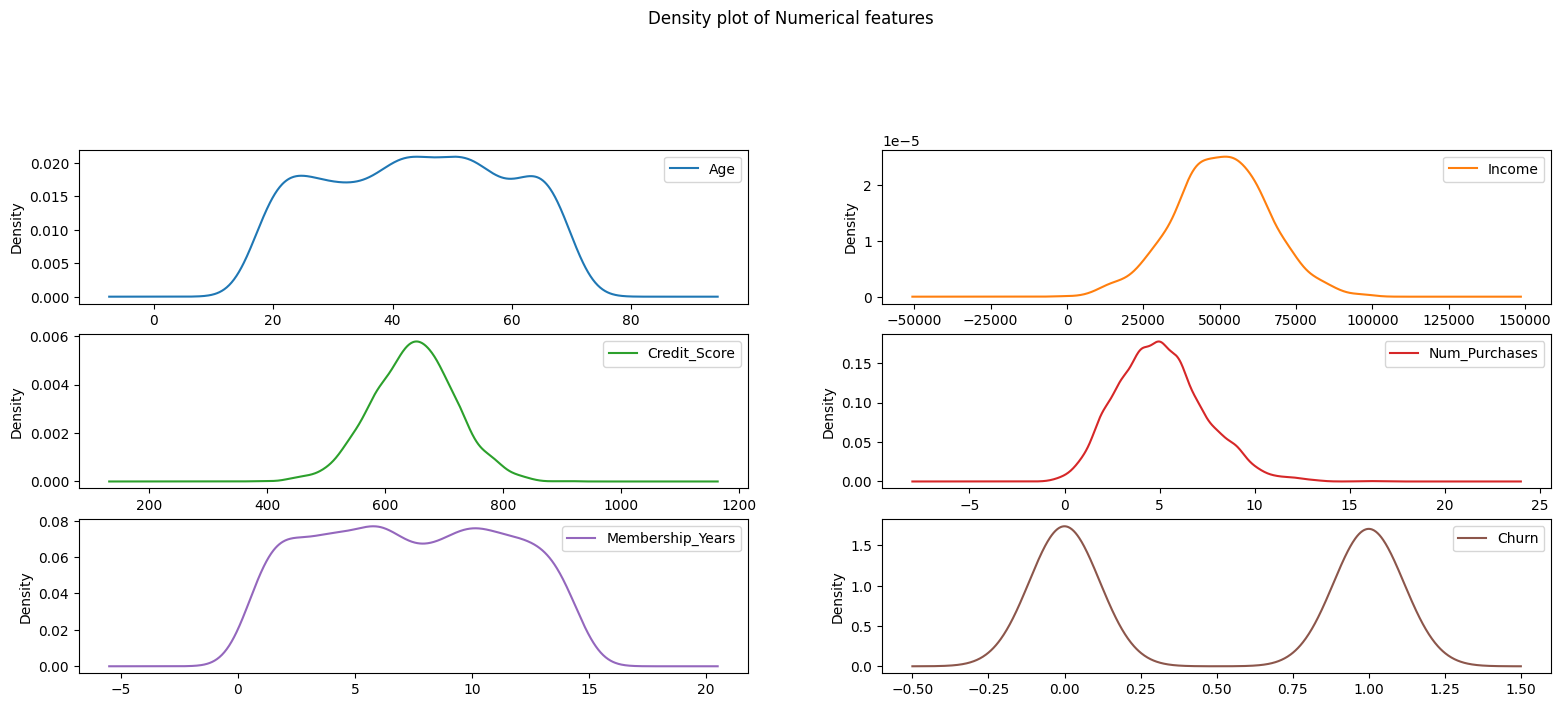

In [ ]:
quantitative_data = dataset.select_dtypes(include= 'number')
quantitative_data.plot(kind='density',figsize=(19,14),subplots=True,layout=(6,2),title="Density plot of Numerical features", sharex = False)
plt.show()

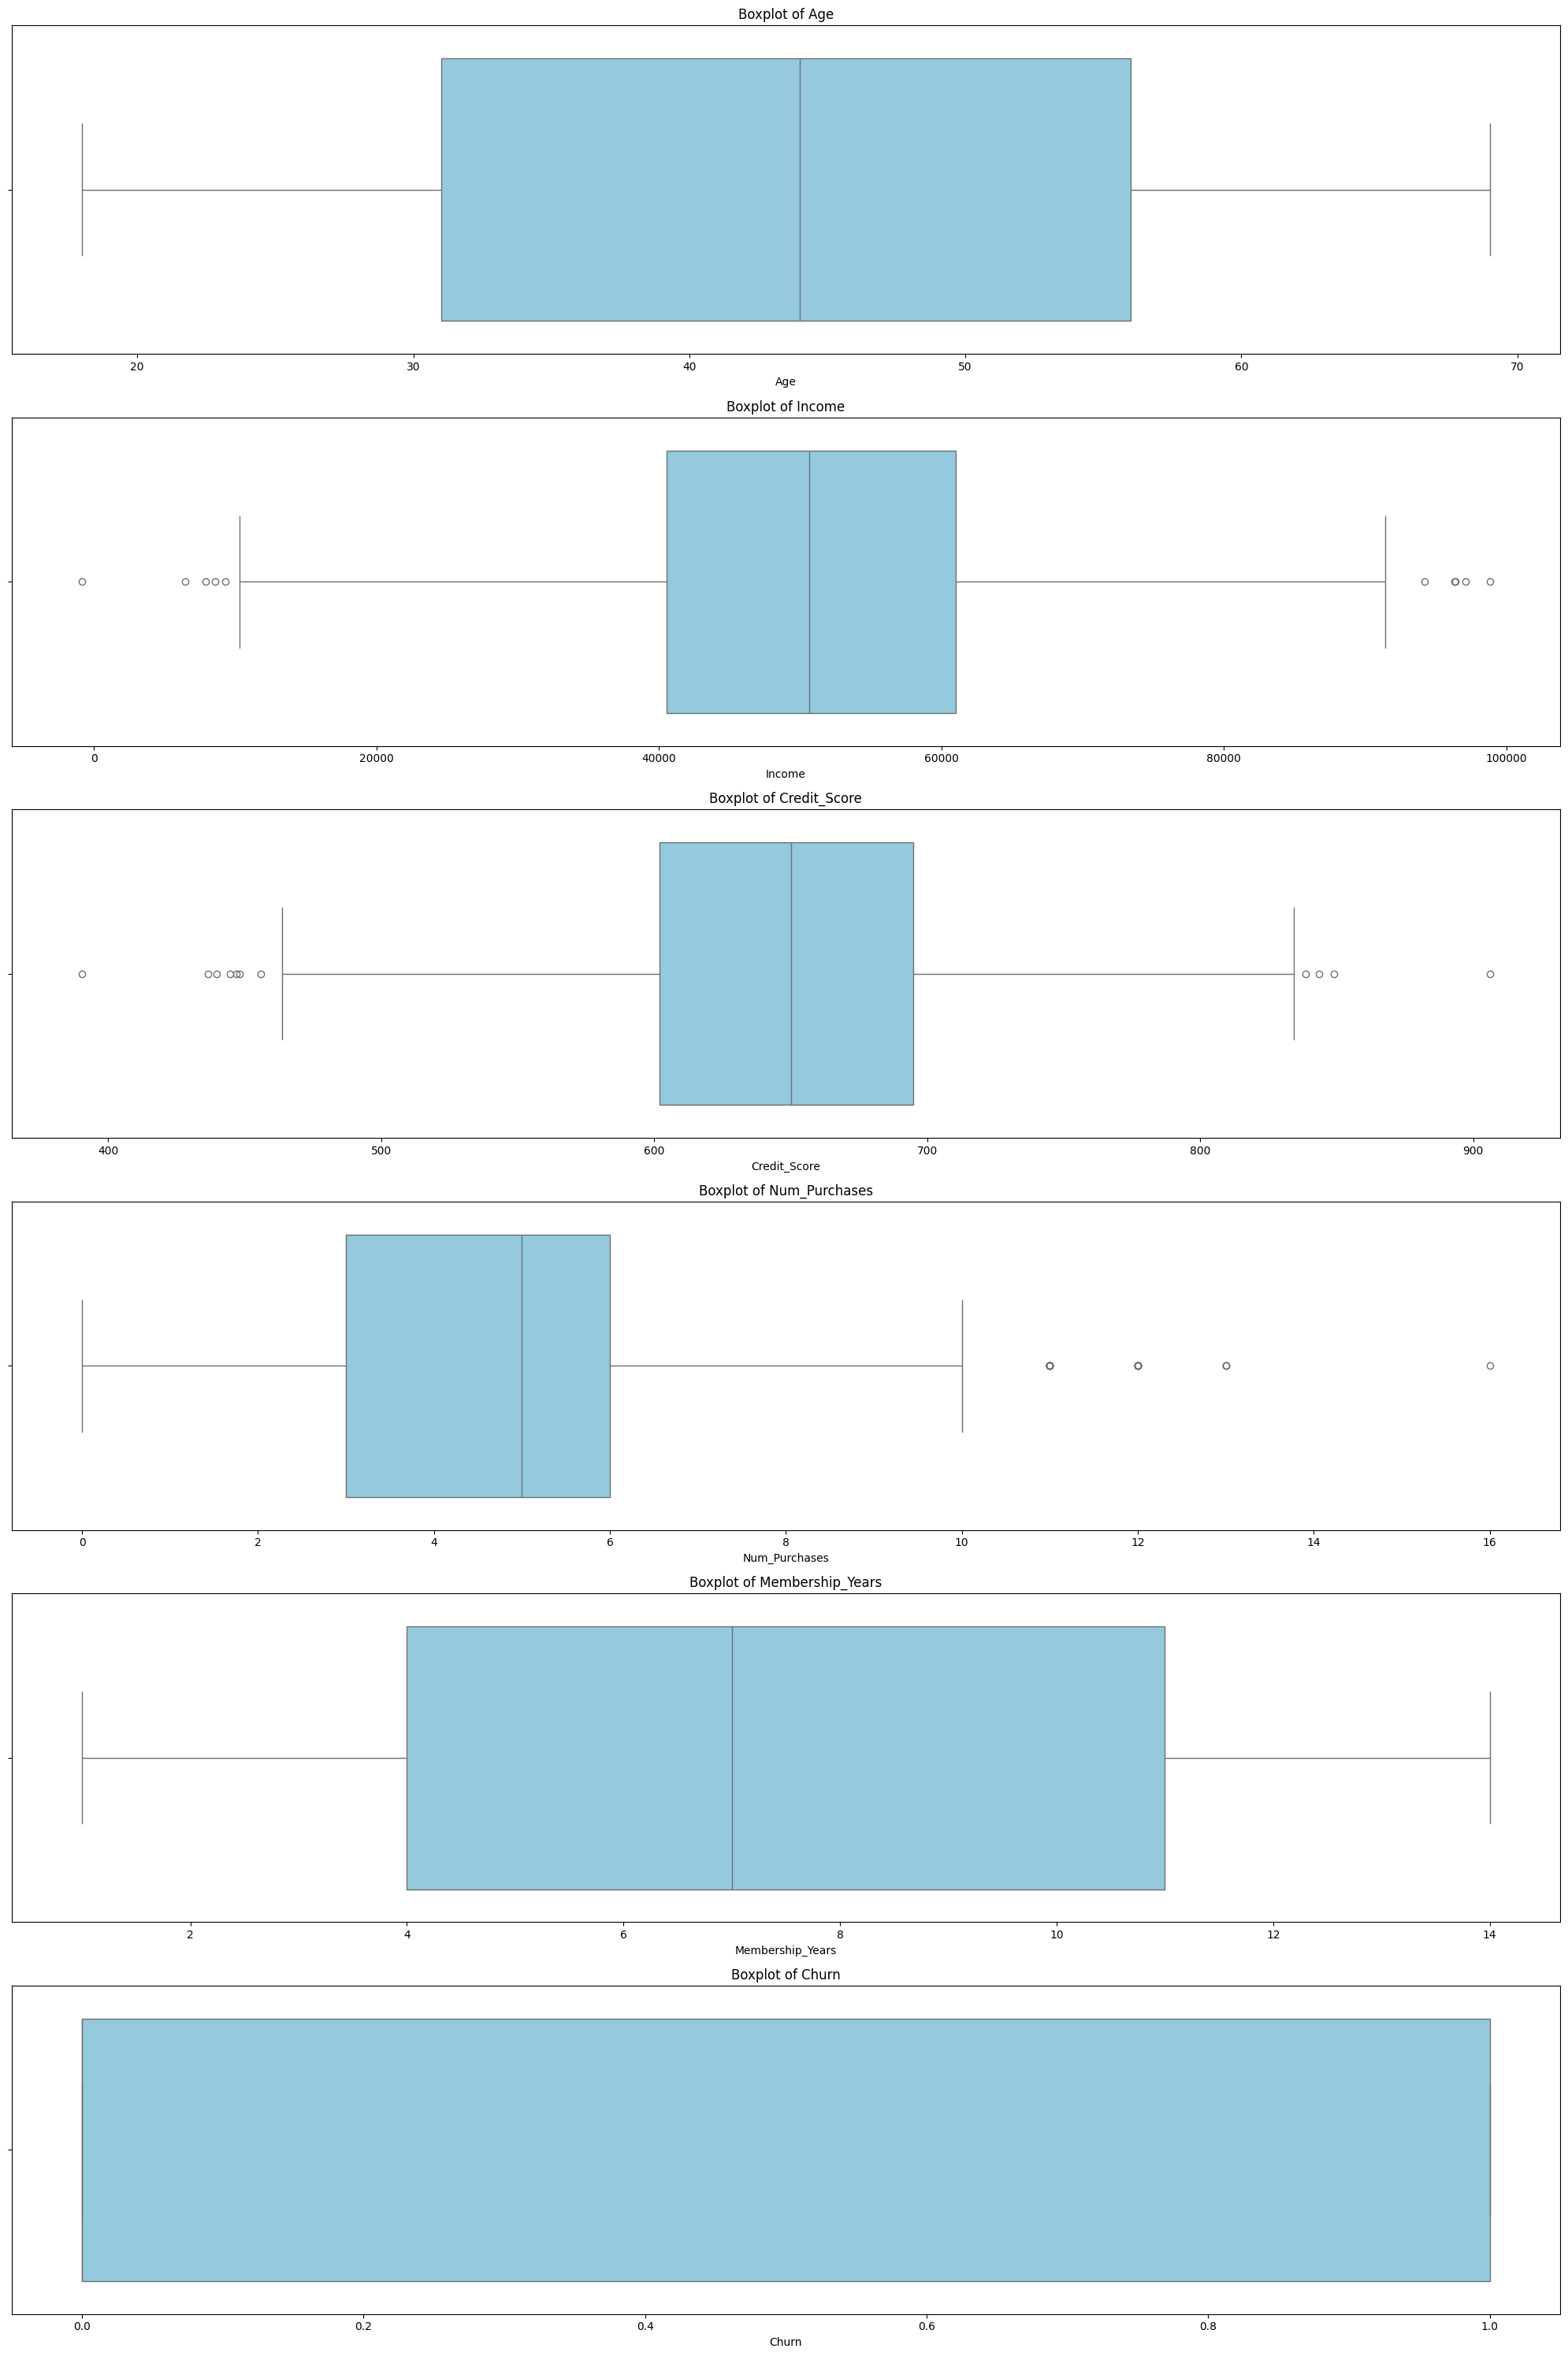

In [ ]:
# Select only numerical columns for boxplot analysis
quantitative_cols = dataset.select_dtypes(include=['int64', 'float64']).columns

# Set up the figure
plt.figure(figsize=(20, 30))

# Plot boxplots for each numerical feature including the target variable 'OUTCOME'
for i, col in enumerate(quantitative_cols, 1):
    plt.subplot(len(quantitative_cols), 1, i)
    sns.boxplot(x=dataset[col], color='skyblue')
    plt.title(f'Boxplot of {col}', fontsize=12)
    plt.tight_layout()

plt.show()

In [ ]:
#Number Unique values in quantitative feature
quantitative_data.nunique()

,0
Age,52
Income,1425
Credit_Score,1425
Num_Purchases,15
Membership_Years,14
Churn,2


In [ ]:
#Number Unique values in quantitative feature
categorical_data.nunique()

,0
Gender,3
Marital_Status,3
Device_Used,3


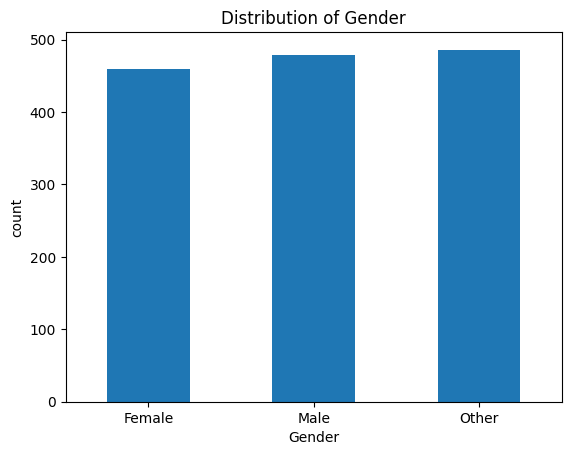

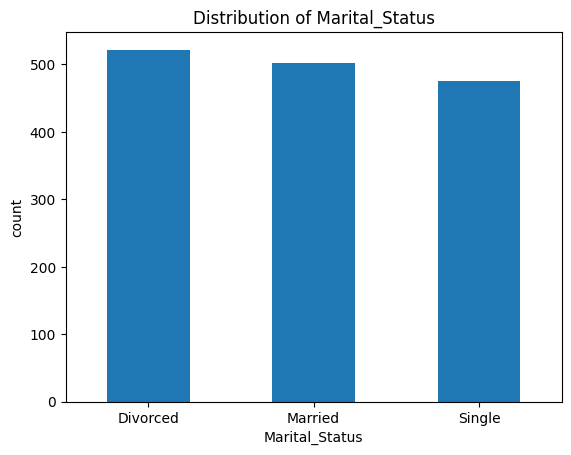

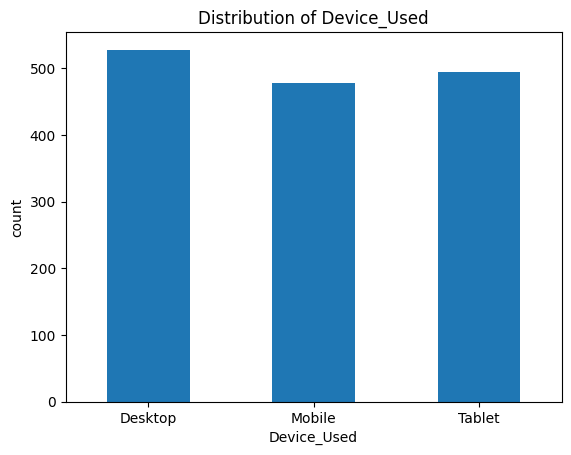

In [ ]:
#Barplot of unique value counts in every categorical features
for col in categorical_features:
    plt.title(f'Distribution of {col}')
    categorical_data[col].value_counts().sort_index().plot(kind='bar', rot=0, xlabel=col,ylabel='count')
    plt.show()

**2.Correlation Analysis**

In [ ]:
# Calculate the correlation matrix
correlation_matrix = quantitative_data.corr()
correlation_matrix

,Age,Income,Credit_Score,Num_Purchases,Membership_Years,Churn
Age,1.000000,0.015700,-0.010746,0.025846,-0.019024,0.006202
Income,0.015700,1.000000,0.013684,-0.009576,0.009499,0.026626
Credit_Score,-0.010746,0.013684,1.000000,0.000861,0.011292,0.019973
Num_Purchases,0.025846,-0.009576,0.000861,1.000000,0.032381,-0.032126
Membership_Years,-0.019024,0.009499,0.011292,0.032381,1.000000,0.001416
Churn,0.006202,0.026626,0.019973,-0.032126,0.001416,1.000000


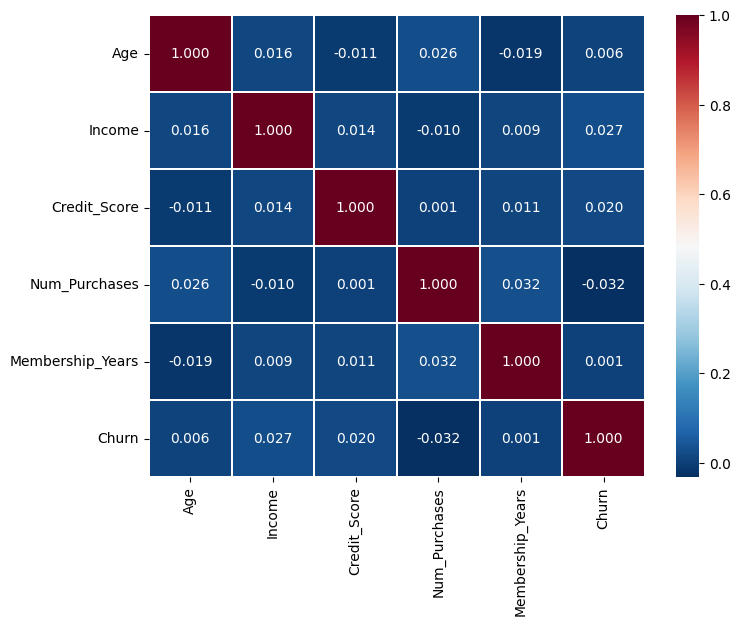

In [ ]:
# Plotting the heatmap for correlation matrix
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='RdBu_r', fmt='.3f', linewidths=0.3)
plt.show()

**Check imbalance in the data**

In [ ]:
#Imbalace Check

#group instances based on the classes in OUTCOME variable
class_counts=dataset.groupby("Churn").size()

columns=['outcome','count','percentage']
outcome=[0,1]
count=list()
percentage=list()

#Calculate the percentage of each value of the OUTCOME variable from total
for val in range(2):
    count.append(class_counts[val])
    percent=(class_counts[val]/1500)*100
    percentage.append(percent)

# Convert the calulated values into a dataframe
imbalance_df=pd.DataFrame(list(zip(outcome,count,percentage)),columns=columns)
imbalance_df

,outcome,count,percentage
0,0,757,50.466667
1,1,743,49.533333


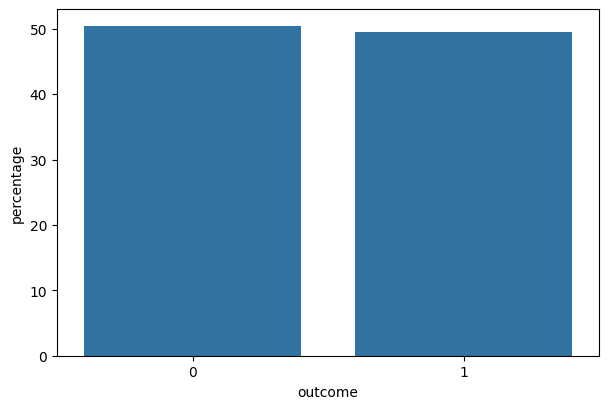

In [ ]:
#Bar Chart plot
plt.figure(figsize=(7,4.5))
sns.barplot(data=imbalance_df,x=imbalance_df['outcome'],y=imbalance_df['percentage'])
plt.show()

**Observations:**

Based on the above grouping, it shows that around 50.5% of instances have OUTCOME value ‘0’ (757 cases) and 49.5% have OUTCOME value ‘1’ (743 cases).

The bar chart shows that the outcome classes are nearly balanced: the bar for class 0 (stayed means active) is only slightly taller than class 1 (churned means inactive).

**Dataset pre-processing**

**1.Null Values**

In [ ]:
null=dataset.isnull().sum()
null_pct = (null / len(df3) * 100).round(2)
null_table = pd.DataFrame({"null(0)": null, "null_%": null_pct})
print(null_table)

                  null(0)  null_%
Age                    75     5.0
Income                 75     5.0
Gender                 75     5.0
Marital_Status          0     0.0
Credit_Score           75     5.0
Num_Purchases           0     0.0
Membership_Years        0     0.0
Device_Used             0     0.0
Churn                   0     0.0


In [ ]:
NULL = dataset.isnull().sum().sum()
print(f"Total NULL Values: {NULL}")

Total NULL Values: 300


In [ ]:
dataset.shape

(1500, 9)

**Handling Null Values**

Removing Columns

In [ ]:
column_null_values = dataset.isnull().sum()
print("Null values per column:\n", column_null_values)

Null values per column:
 Age                 75
Income              75
Gender              75
Marital_Status       0
Credit_Score        75
Num_Purchases        0
Membership_Years     0
Device_Used          0
Churn                0
dtype: int64


In [ ]:
null_cols = dataset.columns[dataset.isna().any()].tolist()
print(null_cols)

['Age', 'Income', 'Gender', 'Credit_Score']


In [ ]:
print("Not removing columns.")
print("Each of those columns has 75 / 1500 = 5% missing. So dropping columns would throw away useful features.")

Not removing columns.
Each of those columns has 75 / 1500 = 5% missing. So dropping columns would throw away useful features.


Removing Rows

In [ ]:
row_null_values = dataset.isnull().sum(axis=1)
print("Null values per row:\n", row_null_values)

Null values per row:
 0       0
1       0
2       0
3       0
4       1
       ..
1495    0
1496    0
1497    0
1498    0
1499    1
Length: 1500, dtype: int64


In [ ]:
len(dataset)

1500

In [ ]:
null_rows = dataset.isnull().any(axis=1).sum()
print(null_rows)

280


In [ ]:
print("Not removing rows.")
print("280 / 1500 = 18.67% of rows with at least one null—dropping them would throw away ~19% of your data and can skew distributions.")

Not removing rows.
280 / 1500 = 18.67% of rows with at least one null—dropping them would throw away ~19% of your data and can skew distributions.


In [ ]:
row_nulls = df3.isna().sum(axis=1)
max_nulls = row_nulls.max()
print("Rows with most nulls:\n", row_nulls[row_nulls == max_nulls])

Rows with most nulls:
 49      2
80      2
104     2
149     2
214     2
225     2
298     2
482     2
638     2
658     2
791     2
831     2
858     2
996     2
1061    2
1093    2
1111    2
1136    2
1168    2
1384    2
dtype: int64


In [ ]:
df1=dataset.copy()

In [ ]:
print("Before drop", df1.shape)
idx_to_drop = row_nulls.idxmax()
df1 = df1.drop(index=idx_to_drop)
print("After drop", df1.shape)

Before drop (1500, 9)
After drop (1499, 9)


**Imputing values**

**1.Putting a fixed value in Null**

In [ ]:
df2 = dataset.copy()

In [ ]:
null_count = df2[df2["Gender"].isnull()]
print("\n Before replacement (Gender) rows with null values:", len(null_count))

fix_value = "Unknown"
df2["Gender"].fillna(fix_value, inplace=True)

rows_filled = df2.loc[null_count.index, ["Gender"]].copy()
rows_filled.insert(0, "row_index", null_count.index)
print("\nAfter replacement (Gender) rows:")
print(rows_filled)

null_count = df2[df2["Gender"].isnull()]
print("After replacement (Gender) rows with null values:", len(null_count))


 Before replacement (Gender) rows with null values: 75

After replacement (Gender) rows:
      row_index   Gender
6             6  Unknown
11           11  Unknown
44           44  Unknown
49           49  Unknown
80           80  Unknown
...         ...      ...
1351       1351  Unknown
1357       1357  Unknown
1384       1384  Unknown
1410       1410  Unknown
1426       1426  Unknown

[75 rows x 2 columns]
After replacement (Gender) rows with null values: 0


/tmp/ipython-input-2179607648.py:5: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df2["Gender"].fillna(fix_value, inplace=True)


**Using mean value - Quantitative Data**

In [ ]:
col = "Credit_Score"  # pick any numeric column in your dataset

nan_count = df2[df2[col].isna()]
print(f"Rows with NaN before replacement ({col}):", len(nan_count))
print(f"\nRows (index, {col}) before:\n", df2.loc[nan_count.index, [col]])

mean_val = df2[col].mean(skipna=True)
df2.loc[:, col] = df2[col].fillna(mean_val)

filled_rows = df2.loc[nan_count.index, [col]]
print(f"\nMean used for {col}: {mean_val:.2f}")
print(f"\nRows after replacement ({col}):\n", filled_rows)

nan_after = df2[df2[col].isna()]
print(f"\nRows with NaN after replacement ({col}):", len(nan_after))

Rows with NaN before replacement (Credit_Score): 75

Rows (index, Credit_Score) before:
       Credit_Score
9              NaN
22             NaN
47             NaN
80             NaN
115            NaN
...            ...
1417           NaN
1425           NaN
1427           NaN
1463           NaN
1499           NaN

[75 rows x 1 columns]

Mean used for Credit_Score: 648.79

Rows after replacement (Credit_Score):
       Credit_Score
9       648.786794
22      648.786794
47      648.786794
80      648.786794
115     648.786794
...            ...
1417    648.786794
1425    648.786794
1427    648.786794
1463    648.786794
1499    648.786794

[75 rows x 1 columns]

Rows with NaN after replacement (Credit_Score): 0


In [ ]:
col = "Age"  # pick any numeric column in your dataset

nan_count = df2[df2[col].isna()]
print(f"Rows with NaN before replacement ({col}):", len(nan_count))
print(f"\nRows (index, {col}) before:\n", df2.loc[nan_count.index, [col]])

mean_val = df2[col].mean(skipna=True)
df2.loc[:, col] = df2[col].fillna(mean_val)

filled_rows = df2.loc[nan_count.index, [col]]
print(f"\nMean used for {col}: {mean_val:.2f}")
print(f"\nRows after replacement ({col}):\n", filled_rows)

nan_after = df2[df2[col].isna()]
print(f"\nRows with NaN after replacement ({col}):", len(nan_after))

Rows with NaN before replacement (Age): 75

Rows (index, Age) before:
       Age
4     NaN
23    NaN
68    NaN
69    NaN
111   NaN
...   ...
1397  NaN
1405  NaN
1413  NaN
1415  NaN
1471  NaN

[75 rows x 1 columns]

Mean used for Age: 43.75

Rows after replacement (Age):
             Age
4     43.750175
23    43.750175
68    43.750175
69    43.750175
111   43.750175
...         ...
1397  43.750175
1405  43.750175
1413  43.750175
1415  43.750175
1471  43.750175

[75 rows x 1 columns]

Rows with NaN after replacement (Age): 0


In [ ]:
col = "Income"  # pick any numeric column in your dataset

nan_count = df2[df2[col].isna()]
print(f"Rows with NaN before replacement ({col}):", len(nan_count))
print(f"\nRows (index, {col}) before:\n", df2.loc[nan_count.index, [col]])

mean_val = df2[col].mean(skipna=True)
df2.loc[:, col] = df2[col].fillna(mean_val)

filled_rows = df2.loc[nan_count.index, [col]]
print(f"\nMean used for {col}: {mean_val:.2f}")
print(f"\nRows after replacement ({col}):\n", filled_rows)

nan_after = df2[df2[col].isna()]
print(f"\nRows with NaN after replacement ({col}):", len(nan_after))

Rows with NaN before replacement (Income): 75

Rows (index, Income) before:
       Income
49       NaN
104      NaN
108      NaN
118      NaN
126      NaN
...      ...
1448     NaN
1449     NaN
1464     NaN
1475     NaN
1489     NaN

[75 rows x 1 columns]

Mean used for Income: 50446.15

Rows after replacement (Income):
             Income
49    50446.150664
104   50446.150664
108   50446.150664
118   50446.150664
126   50446.150664
...            ...
1448  50446.150664
1449  50446.150664
1464  50446.150664
1475  50446.150664
1489  50446.150664

[75 rows x 1 columns]

Rows with NaN after replacement (Income): 0


**Categorical Encoding**

**Label Encoding**

In [ ]:
enc = LabelEncoder()

In [ ]:
df2["Gender_enc"] = enc.fit_transform(df2["Gender"])

# Compare original vs encoded
print(df2[["Gender", "Gender_enc"]].head(6))

df2['Gender'] = df2['Gender_enc']
df2 = df2.drop(['Gender_enc'], axis = 1)

   Gender  Gender_enc
0  Female           0
1    Male           1
2    Male           1
3  Female           0
4   Other           2
5  Female           0


In [ ]:
df2["Marital_Status_enc"] = enc.fit_transform(df2["Marital_Status"])

# Compare original vs encoded
print(df2[["Marital_Status", "Marital_Status_enc"]].head(6))

df2['Marital_Status'] = df2['Marital_Status_enc']
df2 = df2.drop(['Marital_Status_enc'], axis = 1)

  Marital_Status  Marital_Status_enc
0        Married                   1
1         Single                   2
2        Married                   1
3         Single                   2
4        Married                   1
5       Divorced                   0


In [ ]:
df2["Device_Used_enc"] = enc.fit_transform(df2["Device_Used"])

# Compare original vs encoded
print(df2[["Device_Used", "Device_Used_enc"]].head(6))

df2['Device_Used'] = df2['Device_Used_enc']
df2 = df2.drop(['Device_Used_enc'], axis = 1)

  Device_Used  Device_Used_enc
0     Desktop                0
1      Tablet                2
2      Mobile                1
3      Tablet                2
4     Desktop                0
5     Desktop                0


In [ ]:
print(df2)

            Age        Income  Gender  Marital_Status  Credit_Score  \
0     56.000000  70201.189680       0               1    687.761776   
1     69.000000  51901.897395       1               2    712.617115   
2     46.000000  38605.409293       1               1    782.299643   
3     32.000000  49949.736955       0               2    697.749518   
4     43.750175  48965.290095       2               1    663.155216   
...         ...           ...     ...             ...           ...   
1495  40.000000  38575.311408       1               2    717.997517   
1496  54.000000  47273.370862       2               2    678.621530   
1497  28.000000  52600.121356       2               0    611.316046   
1498  23.000000  63187.644522       0               0    690.256745   
1499  35.000000  47717.000295       2               0    648.786794   

      Num_Purchases  Membership_Years  Device_Used  Churn  
0                 9                12            0      0  
1                 3        

**Feature Scaling**

In [ ]:
df4=df2.copy() #After applying Label Encoding dataset

# Separate features and target
X = df4.drop(columns=["Churn"])
y = df4["Churn"]

# Scale only TRUE numeric features (avoid label-encoded categoricals)
num_cols = [c for c in ["Age","Income","Credit_Score","Num_Purchases","Membership_Years"] if c in X.columns]

scaler = StandardScaler()
X[num_cols] = scaler.fit_transform(X[num_cols])

print("Scaled columns:", num_cols)

Scaled columns: ['Age', 'Income', 'Credit_Score', 'Num_Purchases', 'Membership_Years']


**Final Preprocessed Dataset**

In [ ]:
# Combine features and target for inspection
df_preprocessed = X.copy()
df_preprocessed['Churn'] = y

# Final shape check
print("Final preprocessed dataset shape:", df_preprocessed.shape)
print(df_preprocessed.head())

Final preprocessed dataset shape: (1500, 9)
            Age    Income  Gender  Marital_Status  Credit_Score  \
0  8.367072e-01  1.323416       0               1      0.574869   
1  1.724654e+00  0.097522       1               2      0.941478   
2  1.536711e-01 -0.793227       1               1      1.969274   
3 -8.025793e-01 -0.033255       0               2      0.722185   
4  9.706526e-16 -0.099205       2               1      0.211930   

   Num_Purchases  Membership_Years  Device_Used  Churn  
0       1.735181          1.160587            0      0  
1      -0.919805          1.663949            2      0  
2      -0.034810          0.153861            1      0  
3       0.850185         -1.607908            2      0  
4      -0.477307         -0.852864            0      1  


**Dataset Splitting**

In [ ]:
df5 = df_preprocessed.copy()

In [ ]:
X = df5.drop('Churn', axis=1)   # all columns except the target
y = df5['Churn']               # target column

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

In [ ]:
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

X_train shape: (1200, 8)
y_train shape: (1200,)


In [ ]:
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_test shape: (300, 8)
y_test shape: (300,)


In [ ]:
scaler = StandardScaler()
scaler.fit(X_train)

StandardScaler()

In [ ]:
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
print("per-feature minimum before scaling:\n {}".format(X_train.min(axis=0)))
print("per-feature maximum before scaling:\n {}".format(X_train.max(axis=0)))

per-feature minimum before scaling:
 Age                -1.758830
Income             -3.434816
Gender              0.000000
Marital_Status      0.000000
Credit_Score       -3.811359
Num_Purchases      -2.247298
Membership_Years   -1.607908
Device_Used         0.000000
dtype: float64
per-feature maximum before scaling:
 Age                 1.724654
Income              3.240608
Gender              3.000000
Marital_Status      2.000000
Credit_Score        2.951049
Num_Purchases       4.832664
Membership_Years    1.663949
Device_Used         2.000000
dtype: float64


In [ ]:
print("per-feature minimum after scaling:\n {}".format(X_train_scaled.min(axis=0)))
print("per-feature maximum after scaling:\n {}".format(X_train_scaled.max(axis=0)))

per-feature minimum after scaling:
 [-1.75386009 -3.46187941 -1.26057485 -1.19712156 -3.84135229 -2.29239142
 -1.61165654 -1.19564576]
per-feature maximum after scaling:
 [1.71604162 3.24761709 2.07378919 1.23770196 2.96410132 4.89472733
 1.6615946  1.23617613]


array([[<Axes: xlabel='Age', ylabel='Age'>,
        <Axes: xlabel='Income', ylabel='Age'>,
        <Axes: xlabel='Credit_Score', ylabel='Age'>,
        <Axes: xlabel='Num_Purchases', ylabel='Age'>,
        <Axes: xlabel='Membership_Years', ylabel='Age'>],
       [<Axes: xlabel='Age', ylabel='Income'>,
        <Axes: xlabel='Income', ylabel='Income'>,
        <Axes: xlabel='Credit_Score', ylabel='Income'>,
        <Axes: xlabel='Num_Purchases', ylabel='Income'>,
        <Axes: xlabel='Membership_Years', ylabel='Income'>],
       [<Axes: xlabel='Age', ylabel='Credit_Score'>,
        <Axes: xlabel='Income', ylabel='Credit_Score'>,
        <Axes: xlabel='Credit_Score', ylabel='Credit_Score'>,
        <Axes: xlabel='Num_Purchases', ylabel='Credit_Score'>,
        <Axes: xlabel='Membership_Years', ylabel='Credit_Score'>],
       [<Axes: xlabel='Age', ylabel='Num_Purchases'>,
        <Axes: xlabel='Income', ylabel='Num_Purchases'>,
        <Axes: xlabel='Credit_Score', ylabel='Num_Purchases'>

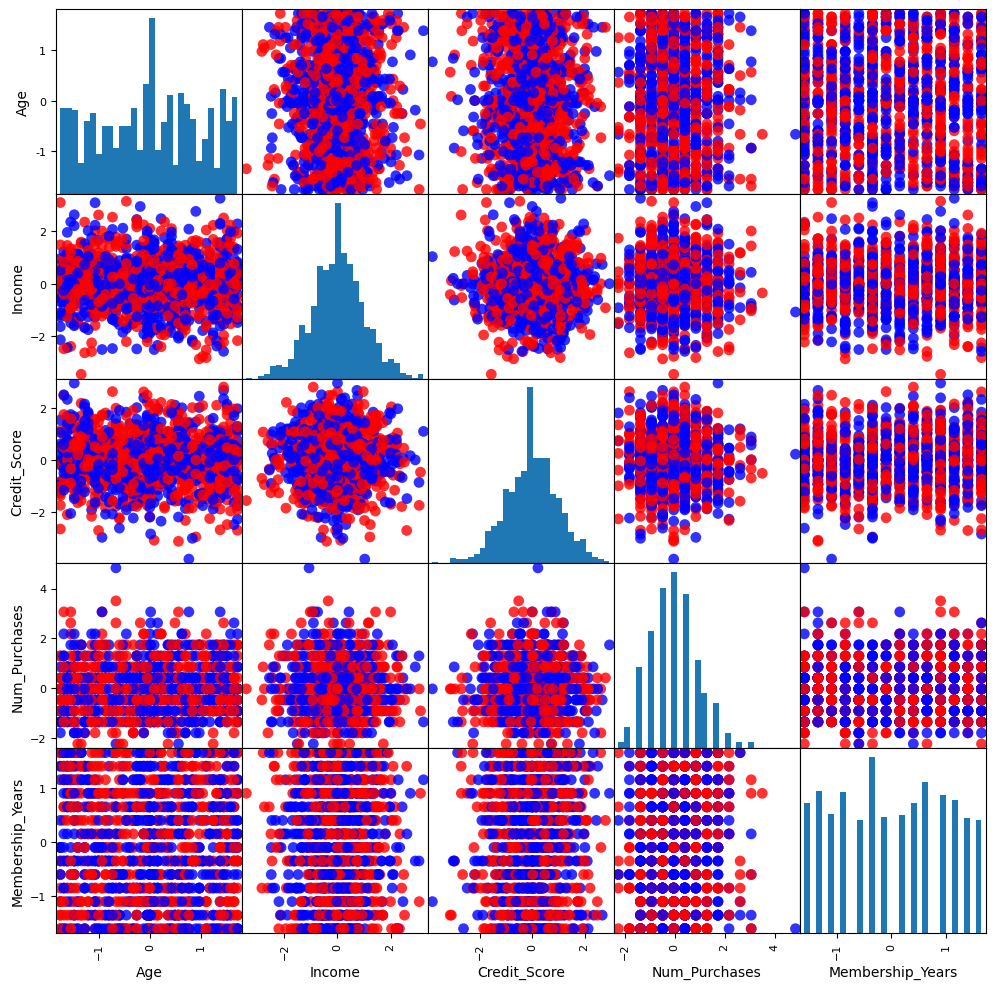

In [ ]:
import pandas as pd

# Pick numeric features from your dataset
selected_features = ['Age', 'Income', 'Credit_Score', 'Num_Purchases', 'Membership_Years']

# Make the plotting frame from your train split
df7 = X_train[selected_features].copy()

# Color by Churn (handles 0/1 or "No"/"Yes")
color_map = {0: 'blue', 1: 'red', 'No': 'blue', 'Yes': 'red'}
y_colors = y_train.map(color_map).fillna('gray')

pd.plotting.scatter_matrix(
    df7,
    c=y_colors,
    figsize=(12, 12),
    marker='o',
    hist_kwds={'bins': 30},
    s=60,
    alpha=0.8
)


**Model Training and Testing**

**KNN**

In [ ]:
knn = KNeighborsClassifier(n_neighbors=30)
knn.fit(X_train_scaled, y_train)

KNeighborsClassifier(n_neighbors=30)

**Neural Network**

In [ ]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Flatten
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import SparseCategoricalCrossentropy

In [ ]:
le = LabelEncoder()
Y_train_numeric = le.fit_transform(y_train)
Y_test_numeric = le.transform(y_test)

In [ ]:
n_features = X_train.shape[1]
n_classes = len(np.unique(Y_train_numeric))

model = Sequential([
    Dense(64, activation='relu', input_shape=(n_features,)),
    Dense(32, activation='relu'),
    Dense(n_classes, activation='softmax')
])

model.compile(
    optimizer=Adam(0.001),
    loss=SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)

history = model.fit(X_train_scaled, Y_train_numeric, epochs=50, batch_size=64)

Epoch 1/50


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4855 - loss: 0.7053   
Epoch 2/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5052 - loss: 0.6935 
Epoch 3/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5316 - loss: 0.6876 
Epoch 4/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5552 - loss: 0.6819 
Epoch 5/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5701 - loss: 0.6790 
Epoch 6/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6004 - loss: 0.6758 
Epoch 7/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5943 - loss: 0.6739 
Epoch 8/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6025 - loss: 0.6726 
Epoch 9/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6082 - loss: 0.6673 
Epoch 10/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6178 - loss: 0.6645 
Epoch 11/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6323 - loss: 0.6587 
Epoch 12/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6054 - 

**Logistic Regression**

In [ ]:
model = LogisticRegression(multi_class='multinomial', solver='lbfgs', max_iter=500)
model.fit(X_train_scaled, Y_train_numeric)

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1237: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, binary problems will be fit as proper binary  logistic regression models (as if multi_class='ovr' were set). Leave it to its default value to avoid this warning.
  warnings.warn(


LogisticRegression(max_iter=500, multi_class='multinomial')

**Model Prediction**

In [ ]:
y_pred1 = knn.predict(X_test_scaled)
print("First 100 test set predictions using KNN:\n", y_pred1[:100])

First 100 test set predictions using KNN:
 [1 1 1 1 1 1 0 1 0 0 0 0 0 1 1 0 1 0 0 0 0 0 0 0 0 0 0 1 0 0 0 1 1 1 0 0 1
 1 1 0 0 1 0 1 1 1 0 0 0 0 1 0 0 0 1 1 0 0 0 0 1 0 0 1 1 1 0 0 0 0 0 0 0 1
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 1 0 1 0 1 0 0 1]


In [ ]:
y_pred_numeric = model.predict(X_test_scaled)
y_pred2 = le.inverse_transform(y_pred_numeric)
print("First 100 test set predictions using Neural Network:\n", y_pred2[:100])

First 100 test set predictions using Neural Network:
 [0 0 0 0 1 1 0 1 0 0 1 0 0 0 1 1 1 1 0 1 0 0 1 1 0 0 1 1 0 0 0 0 1 1 0 0 1
 1 0 0 0 0 0 1 1 1 0 1 0 1 1 1 1 0 1 1 0 1 0 1 0 1 0 1 0 0 1 1 0 0 1 1 1 0
 0 0 1 0 0 0 0 0 0 0 1 1 1 0 1 0 1 1 1 1 0 0 1 0 0 1]


In [ ]:
y_pred_numeric = model.predict(X_test_scaled)
y_pred3 = le.inverse_transform(y_pred_numeric)
print("First 100 test set predictions using Logistic Regression:\n", y_pred3[:100])

First 100 test set predictions using Logistic Regression:
 [0 0 0 0 1 1 0 0 0 0 1 0 0 0 0 0 1 1 0 1 0 0 1 1 0 0 1 1 0 0 0 0 0 1 0 0 1
 0 0 0 0 0 0 1 1 0 0 0 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 1 0 0 0 0 0 0 1 0 1 0
 0 0 1 0 0 0 0 0 0 0 0 1 1 0 0 0 1 1 0 1 0 0 0 0 0 1]


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


**Model Evaluation**

In [ ]:
accuracy = accuracy_score(y_test, y_pred1)
print("Accuracy using KNN: {:.2f}".format(accuracy))

Accuracy using KNN: 0.51


In [ ]:
accuracy = accuracy_score(y_test, y_pred2)
print("Accuracy using Neural Network: {:.2f}".format(accuracy))

Accuracy using Neural Network: 0.48


In [ ]:
accuracy = accuracy_score(y_test, y_pred3)
print("Accuracy using Logistic Regression: {:.2f}".format(accuracy))

Accuracy using Logistic Regression: 0.47


In [ ]:
models = {
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Neural Network": MLPClassifier(hidden_layer_sizes=(50,), max_iter=1000),
    "Logistic Regression": LogisticRegression(max_iter=1000, multi_class="ovr")
}

In [ ]:
# Model Evaluation and Comparison
from sklearn.metrics import (
    f1_score, roc_auc_score, roc_curve, auc,
    classification_report, accuracy_score, precision_score, recall_score
)

# Lists to store evaluation results
model_names = []
f1_scores = []

# Re-train and evaluate models
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    # Save name and F1 score for plotting
    model_names.append(name)
    f1 = f1_score(y_test, y_pred)
    f1_scores.append(f1)

    # Print full evaluation metrics
    print(f"\n🔹 Model: {name}")
    print("Accuracy      :", round(accuracy_score(y_test, y_pred), 4))
    print("Precision     :", round(precision_score(y_test, y_pred), 4))
    print("Recall        :", round(recall_score(y_test, y_pred), 4))
    print("F1 Score      :", round(f1, 4))
    print("ROC AUC Score :", round(roc_auc_score(y_test, y_pred), 4))
    print("\nClassification Report:\n", classification_report(y_test, y_pred, target_names=['Non-Churned', 'Churned']))


🔹 Model: KNN
Accuracy      : 0.47
Precision     : 0.4638
Recall        : 0.4295
F1 Score      : 0.446
ROC AUC Score : 0.4697

Classification Report:
               precision    recall  f1-score   support

 Non-Churned       0.48      0.51      0.49       151
     Churned       0.46      0.43      0.45       149

    accuracy                           0.47       300
   macro avg       0.47      0.47      0.47       300
weighted avg       0.47      0.47      0.47       300


🔹 Model: Neural Network
Accuracy      : 0.51
Precision     : 0.5068
Recall        : 0.5034
F1 Score      : 0.5051
ROC AUC Score : 0.51

Classification Report:
               precision    recall  f1-score   support

 Non-Churned       0.51      0.52      0.51       151
     Churned       0.51      0.50      0.51       149

    accuracy                           0.51       300
   macro avg       0.51      0.51      0.51       300
weighted avg       0.51      0.51      0.51       300


🔹 Model: Logistic Regression
Accu

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1256: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. Use OneVsRestClassifier(LogisticRegression(..)) instead. Leave it to its default value to avoid this warning.
  warnings.warn(


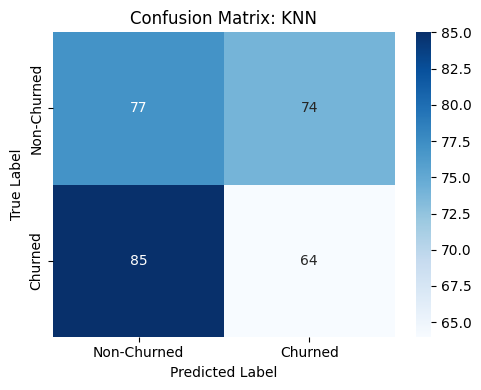

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


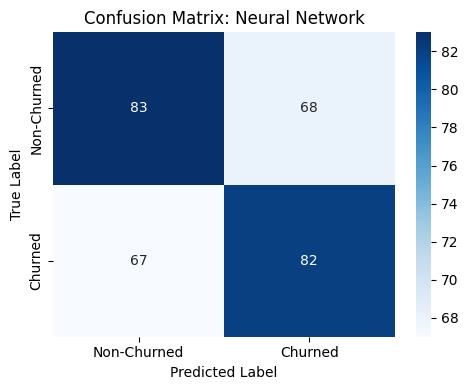

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1256: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. Use OneVsRestClassifier(LogisticRegression(..)) instead. Leave it to its default value to avoid this warning.
  warnings.warn(


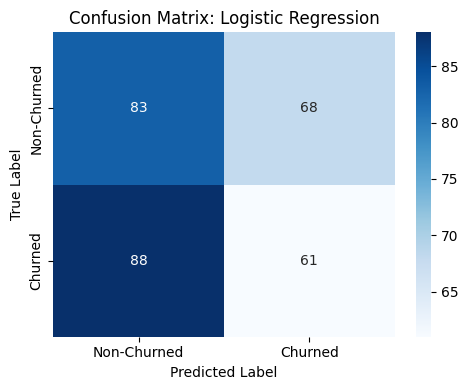

In [ ]:
# Reuse the same models and predictions
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Non-Churned', 'Churned'], yticklabels=['Non-Churned', 'Churned'])
    plt.title(f'Confusion Matrix: {name}')
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.tight_layout()
    plt.show()


**Bar Chart: Model F1 Score Comparison**

/tmp/ipython-input-156941358.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=model_names, y=f1_scores, palette='Set2')


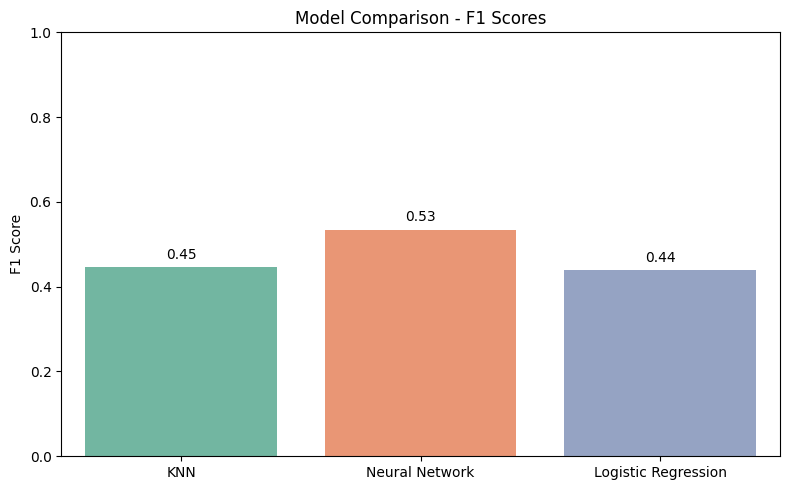

In [ ]:
# Plot bar chart of F1 scores
plt.figure(figsize=(8, 5))
sns.barplot(x=model_names, y=f1_scores, palette='Set2')
plt.title('Model Comparison - F1 Scores')
plt.ylabel('F1 Score')
plt.ylim(0, 1)

# Add value labels above bars
for i, score in enumerate(f1_scores):
    plt.text(i, score + 0.02, f'{score:.2f}', ha='center', fontsize=10)

plt.tight_layout()
plt.show()

**ROC Curves for All Models**

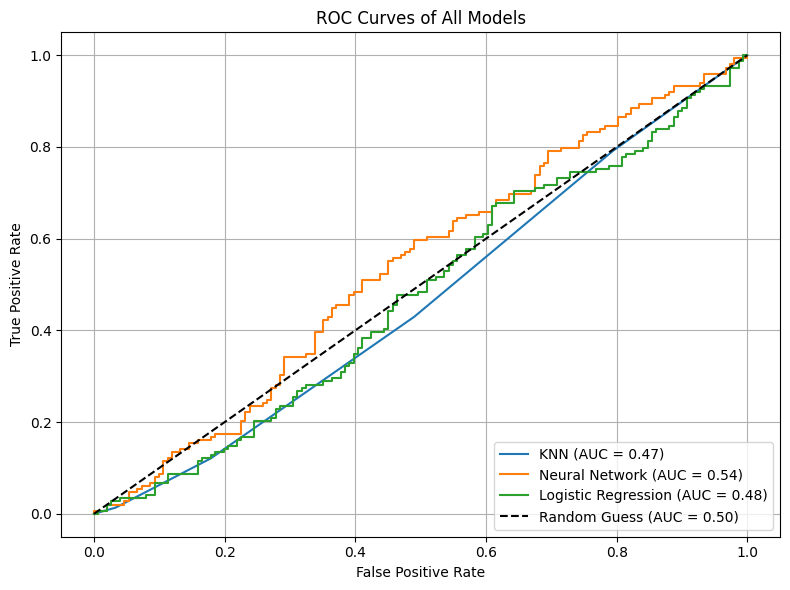

In [ ]:
# Plot ROC curve for each model
plt.figure(figsize=(8, 6))

for name, model in models.items():
    if hasattr(model, "predict_proba"):
        y_scores = model.predict_proba(X_test)[:, 1]
    else:
        y_scores = model.decision_function(X_test)

    fpr, tpr, _ = roc_curve(y_test, y_scores)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc:.2f})")

# Plot random guess baseline
plt.plot([0, 1], [0, 1], 'k--', label='Random Guess (AUC = 0.50)')

plt.title("ROC Curves of All Models")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc='lower right')
plt.grid()
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import roc_auc_score
from sklearn.exceptions import NotFittedError
import numpy as np

# models you already defined (must be the SAME objects you trained)
models = {
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Neural Network": MLPClassifier(hidden_layer_sizes=(50,), max_iter=1000),
    "Logistic Regression": LogisticRegression(max_iter=1000, multi_class="ovr")
}

def proba_or_score(m, X):
    if hasattr(m, "predict_proba"):
        return m.predict_proba(X)[:, 1]
    if hasattr(m, "decision_function"):
        return m.decision_function(X)
    p = m.predict(X)                      # e.g., Keras returns probs
    return np.ravel(p)

scores = {}
for name, m in models.items():
    try:
        y_score = proba_or_score(m, X_test)   # use X_test_scaled if you trained on scaled features
    except NotFittedError:
        m.fit(X_train, y_train)               # fit once if not fitted
        y_score = proba_or_score(m, X_test)
    scores[name] = roc_auc_score(y_test, y_score)

print("AUCs:", {k: round(v, 4) for k, v in scores.items()})
print("Best by AUC:", max(scores, key=scores.get))


AUCs: {'KNN': np.float64(0.4656), 'Neural Network': np.float64(0.531), 'Logistic Regression': np.float64(0.4768)}
Best by AUC: Neural Network


/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1256: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. Use OneVsRestClassifier(LogisticRegression(..)) instead. Leave it to its default value to avoid this warning.
  warnings.warn(


**Unsupervised Learning**

**K-Means Clustering**

In [ ]:
feature_names = dataset.columns.tolist()
df7 = pd.DataFrame(df5, columns=feature_names[1:len(feature_names)-1])

X = df7.values

kmeans = KMeans(n_clusters=4)
df7["cluster"] = kmeans.fit_predict(X)

print(df7["cluster"])

0       2
1       1
2       1
3       3
4       0
       ..
1495    1
1496    0
1497    0
1498    0
1499    0
Name: cluster, Length: 1500, dtype: int32


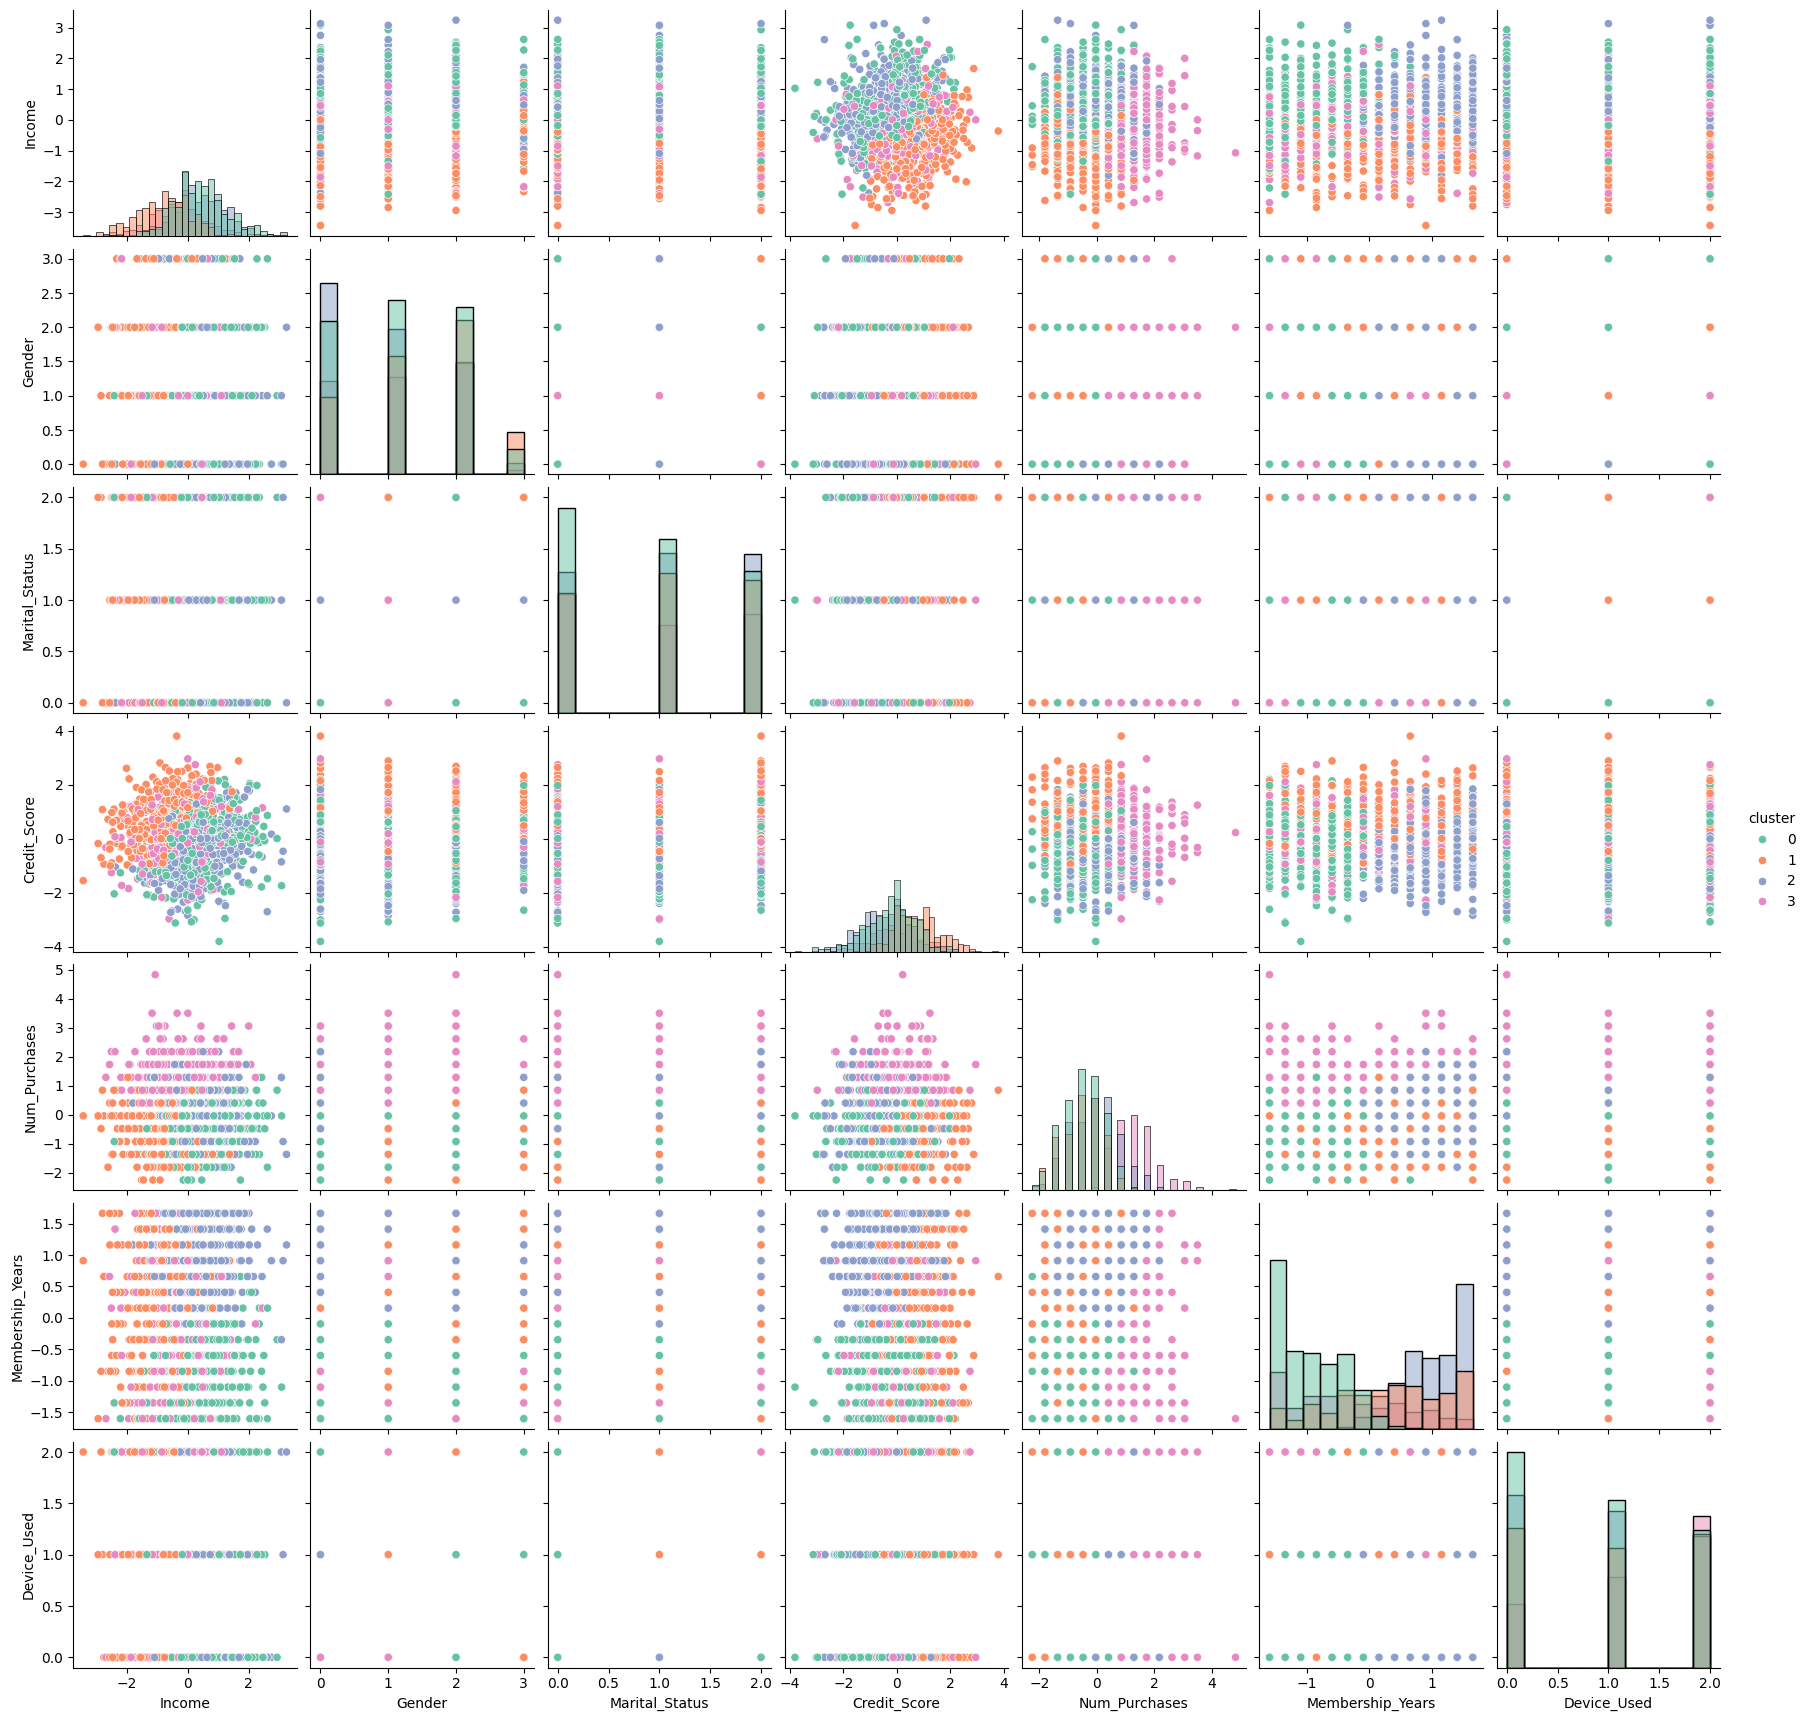

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.pairplot(df7, hue="cluster", diag_kind="hist", palette="Set2")
plt.show()

1


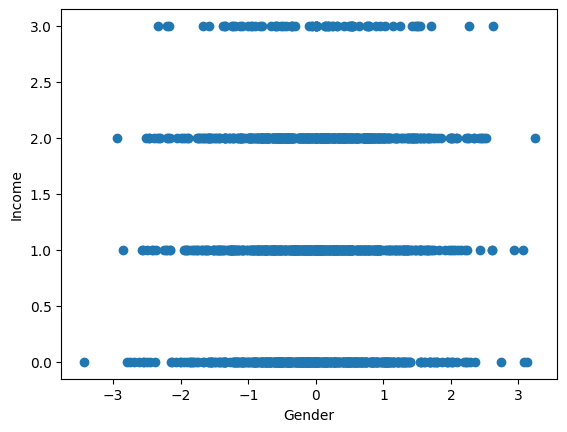

2


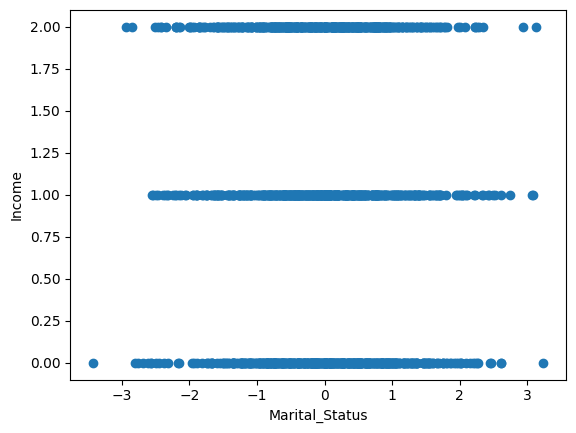

3


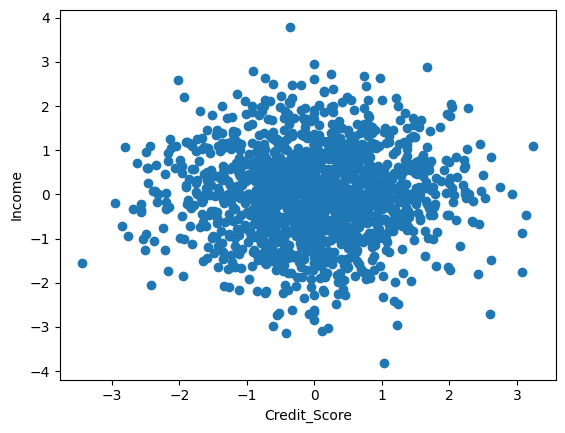

4


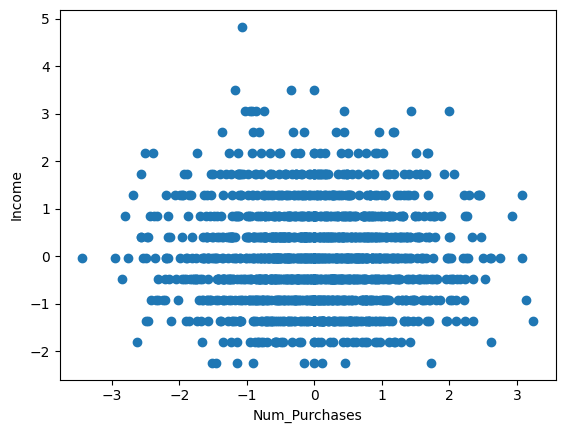

5


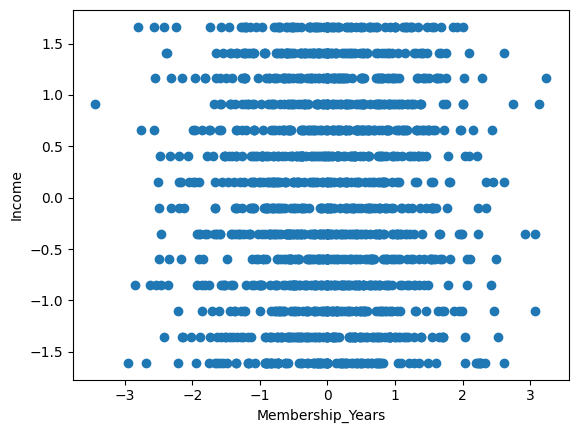

6


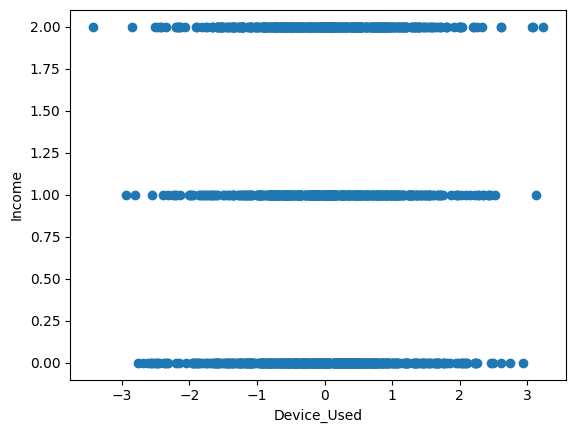

7


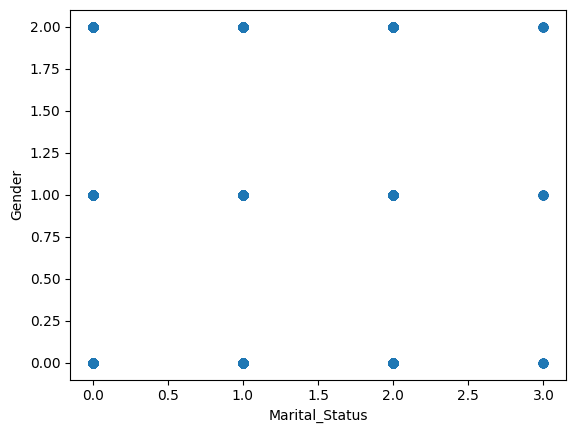

8


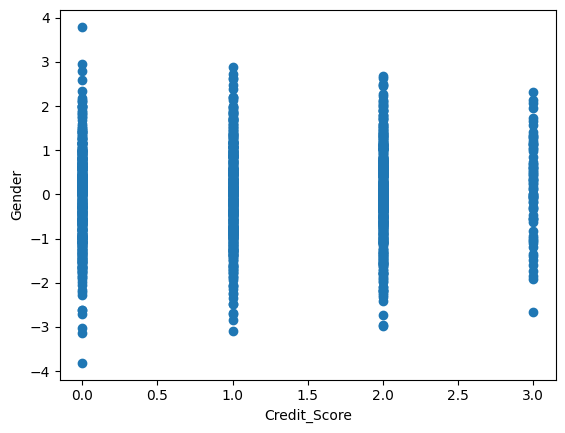

9


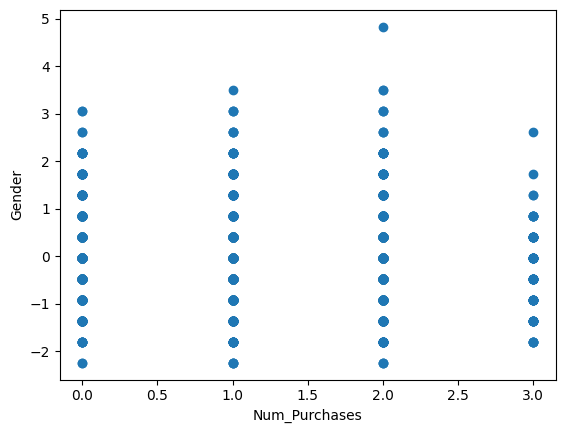

10


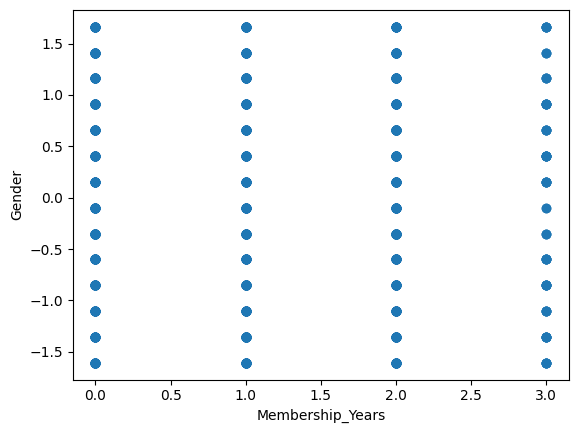

11


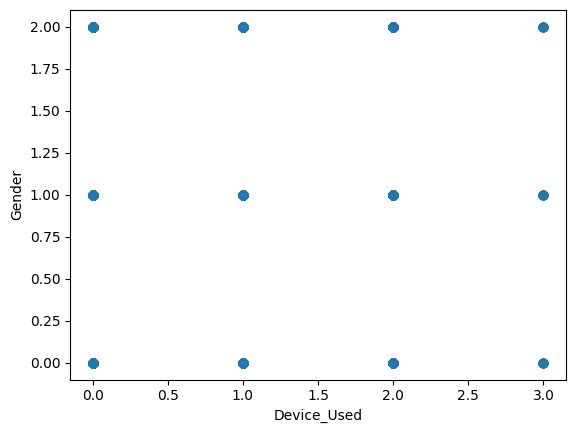

12


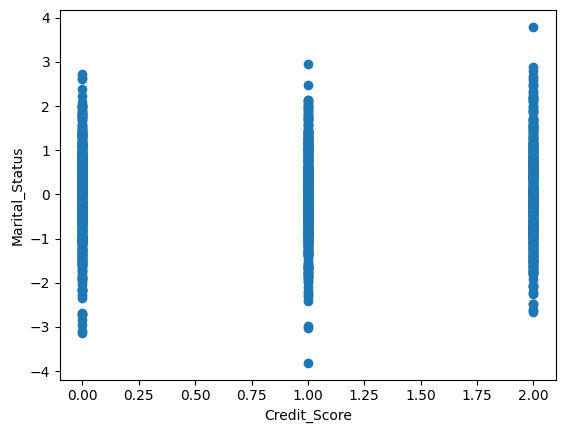

13


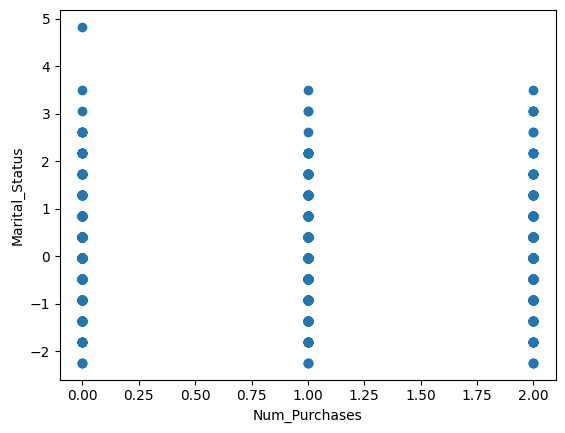

14


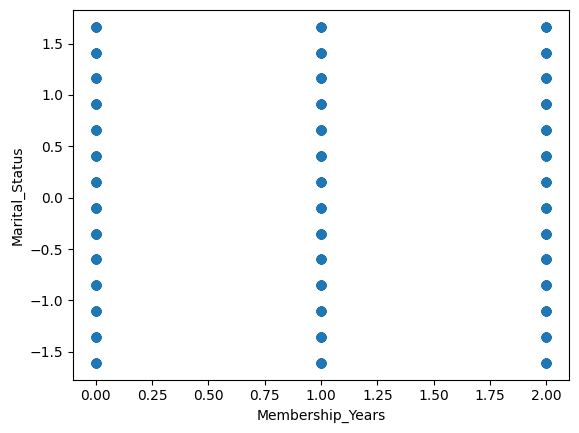

15


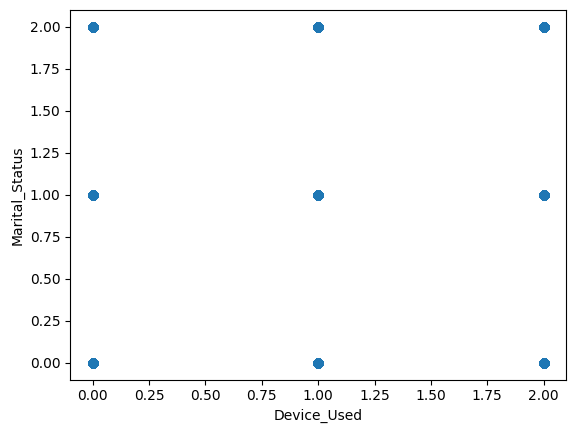

16


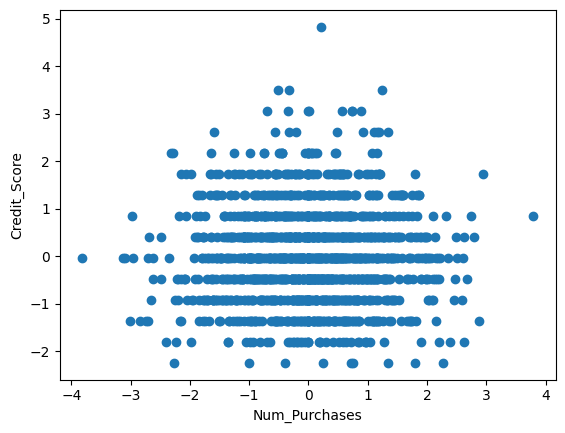

17


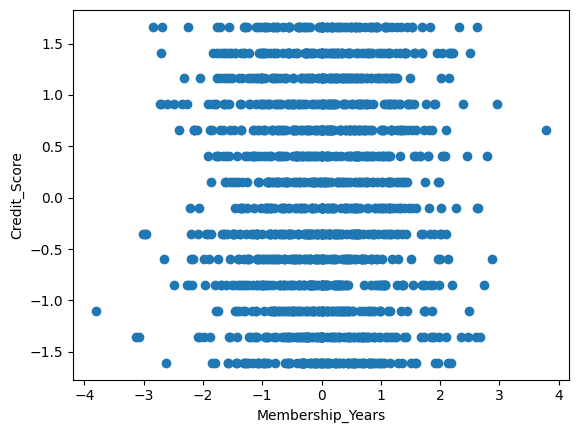

18


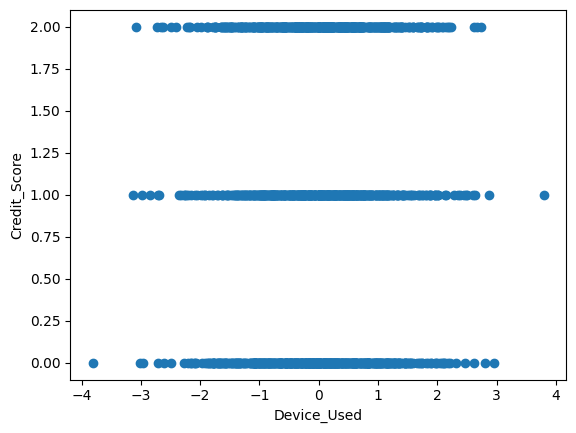

19


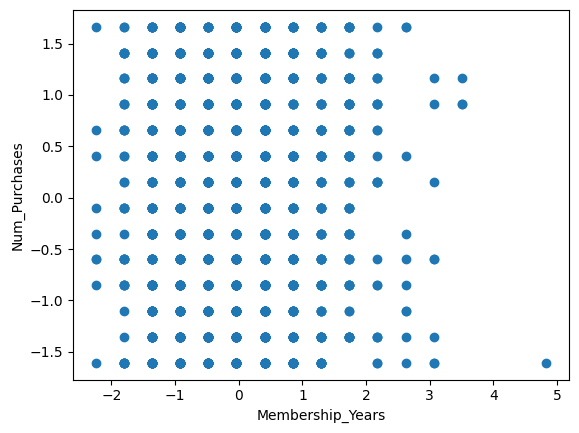

20


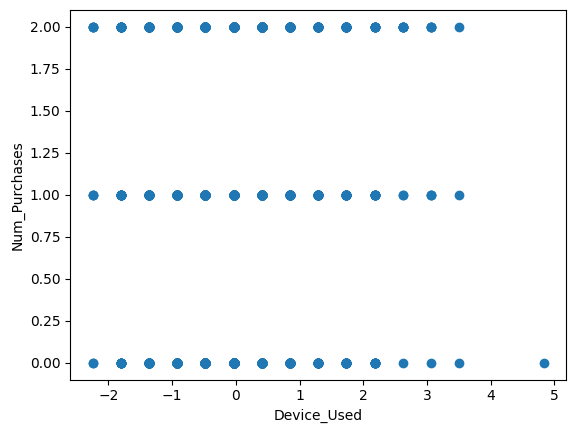

21


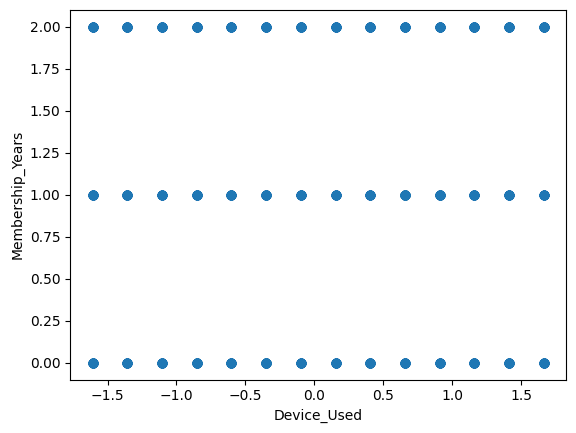

In [ ]:
count = 0
for i in range(1, len(feature_names)-1):
  for j in range(i+1, len(feature_names)-1):
    if i != j:
      count+=1
      print(count)
      plt.ylabel(feature_names[i])
      plt.xlabel(feature_names[j])
      plt.scatter(df7[feature_names[i]],df7[feature_names[j]])
      plt.show()

**In my dataset the numeric features are essentially uncorrelated and 2-cluster K-Means gives weak structure and doesn’t match Churn  so clustering isn’t useful—use supervised models.**